# Vehicles Price Prediction — Linear, Lasso and Ridge Regression

This notebook is based on the uploaded **Project 8 Car Price Prediction** notebook and the **CAR DETAILS FROM CAR DEKHO.csv** dataset.

It includes:
- Exploratory Data Analysis
- Feature engineering using car name, brand and model
- One-hot encoding and standardization
- Linear Regression
- Lasso Regression
- Ridge Regression
- GridSearchCV for Ridge hyperparameter tuning
- R², Adjusted R², MAE, MSE, RMSE and MAPE
- Actual vs predicted plots
- Residual analysis
- Model comparison


In [ ]:
# ============================================================
# 1. IMPORT LIBRARIES
# ============================================================

import pandas as pd
import numpy as np

import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split, GridSearchCV
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.pipeline import Pipeline

from sklearn.linear_model import LinearRegression, Lasso, Ridge

from sklearn.metrics import (
    r2_score,
    mean_absolute_error,
    mean_squared_error,
    mean_absolute_percentage_error
)

pd.set_option("display.max_columns", None)
sns.set_theme(style="whitegrid")

In [ ]:
# ============================================================
# 2. LOAD DATASET
# ============================================================

car_dataset = pd.read_csv("CAR DETAILS FROM CAR DEKHO.csv")

print("Dataset loaded successfully!")
print("Shape:", car_dataset.shape)

Dataset loaded successfully!
Shape: (4340, 8)


In [ ]:
# ============================================================
# 3. BASIC DATA INSPECTION
# ============================================================

display(car_dataset.head())

print("\nDataset shape:")
print(car_dataset.shape)

print("\nDataset information:")
car_dataset.info()

print("\nMissing values:")
print(car_dataset.isnull().sum())

print("\nColumn names:")
print(car_dataset.columns.tolist())

,name,year,selling_price,km_driven,fuel,seller_type,transmission,owner
0,Maruti 800 AC,2007,60000,70000,Petrol,Individual,Manual,First Owner
1,Maruti Wagon R LXI Minor,2007,135000,50000,Petrol,Individual,Manual,First Owner
2,Hyundai Verna 1.6 SX,2012,600000,100000,Diesel,Individual,Manual,First Owner
3,Datsun RediGO T Option,2017,250000,46000,Petrol,Individual,Manual,First Owner
4,Honda Amaze VX i-DTEC,2014,450000,141000,Diesel,Individual,Manual,Second Owner



Dataset shape:
(4340, 8)

Dataset information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 4340 entries, 0 to 4339
Data columns (total 8 columns):
 #   Column         Non-Null Count  Dtype 
---  ------         --------------  ----- 
 0   name           4340 non-null   object
 1   year           4340 non-null   int64 
 2   selling_price  4340 non-null   int64 
 3   km_driven      4340 non-null   int64 
 4   fuel           4340 non-null   object
 5   seller_type    4340 non-null   object
 6   transmission   4340 non-null   object
 7   owner          4340 non-null   object
dtypes: int64(3), object(5)
memory usage: 271.4+ KB

Missing values:
name             0
year             0
selling_price    0
km_driven        0
fuel             0
seller_type      0
transmission     0
owner            0
dtype: int64

Column names:
['name', 'year', 'selling_price', 'km_driven', 'fuel', 'seller_type', 'transmission', 'owner']


In [ ]:
# ============================================================
# 4. STATISTICAL SUMMARY
# ============================================================

display(car_dataset.describe(include="all"))

,name,year,selling_price,km_driven,fuel,seller_type,transmission,owner
count,4340,4340.000000,4.340000e+03,4340.000000,4340,4340,4340,4340
unique,1491,NaN,NaN,NaN,5,3,2,5
top,Maruti Swift Dzire VDI,NaN,NaN,NaN,Diesel,Individual,Manual,First Owner
freq,69,NaN,NaN,NaN,2153,3244,3892,2832
mean,NaN,2013.090783,5.041273e+05,66215.777419,NaN,NaN,NaN,NaN
std,NaN,4.215344,5.785487e+05,46644.102194,NaN,NaN,NaN,NaN
min,NaN,1992.000000,2.000000e+04,1.000000,NaN,NaN,NaN,NaN
25%,NaN,2011.000000,2.087498e+05,35000.000000,NaN,NaN,NaN,NaN
50%,NaN,2014.000000,3.500000e+05,60000.000000,NaN,NaN,NaN,NaN
75%,NaN,2016.000000,6.000000e+05,90000.000000,NaN,NaN,NaN,NaN


In [ ]:
# ============================================================
# 5. CATEGORICAL VARIABLE DISTRIBUTIONS
# ============================================================

for column in ["fuel", "seller_type", "transmission", "owner"]:
    print(f"\n{column.upper()}:")
    print(car_dataset[column].value_counts())


FUEL:
fuel
Diesel      2153
Petrol      2123
CNG           40
LPG           23
Electric       1
Name: count, dtype: int64

SELLER_TYPE:
seller_type
Individual          3244
Dealer               994
Trustmark Dealer     102
Name: count, dtype: int64

TRANSMISSION:
transmission
Manual       3892
Automatic     448
Name: count, dtype: int64

OWNER:
owner
First Owner             2832
Second Owner            1106
Third Owner              304
Fourth & Above Owner      81
Test Drive Car            17
Name: count, dtype: int64


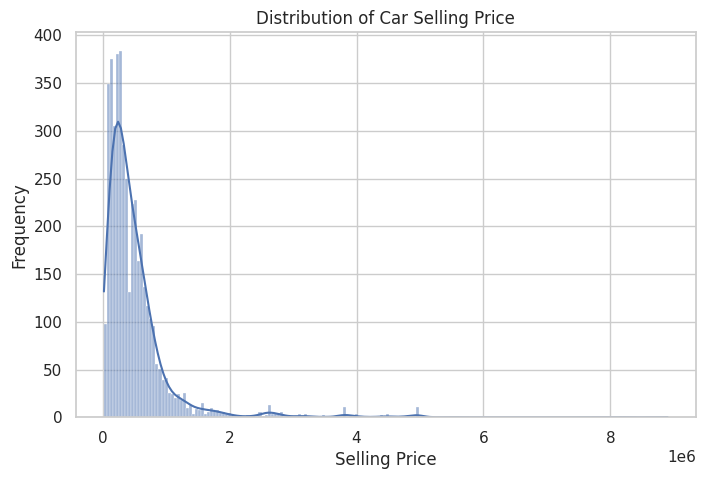

In [ ]:
# ============================================================
# 6. DISTRIBUTION OF SELLING PRICE
# ============================================================

plt.figure(figsize=(8, 5))
sns.histplot(car_dataset["selling_price"], kde=True)
plt.xlabel("Selling Price")
plt.ylabel("Frequency")
plt.title("Distribution of Car Selling Price")
plt.show()

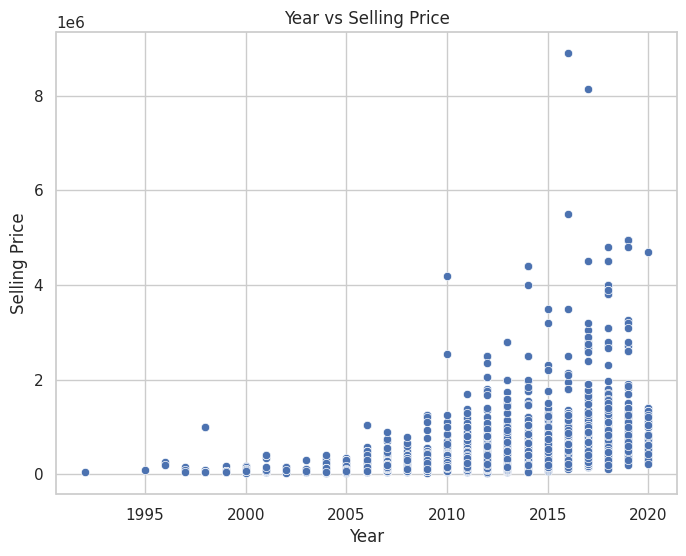

In [ ]:
# ============================================================
# 7. SELLING PRICE VS YEAR
# ============================================================

plt.figure(figsize=(8, 6))
sns.scatterplot(data=car_dataset, x="year", y="selling_price")
plt.xlabel("Year")
plt.ylabel("Selling Price")
plt.title("Year vs Selling Price")
plt.show()

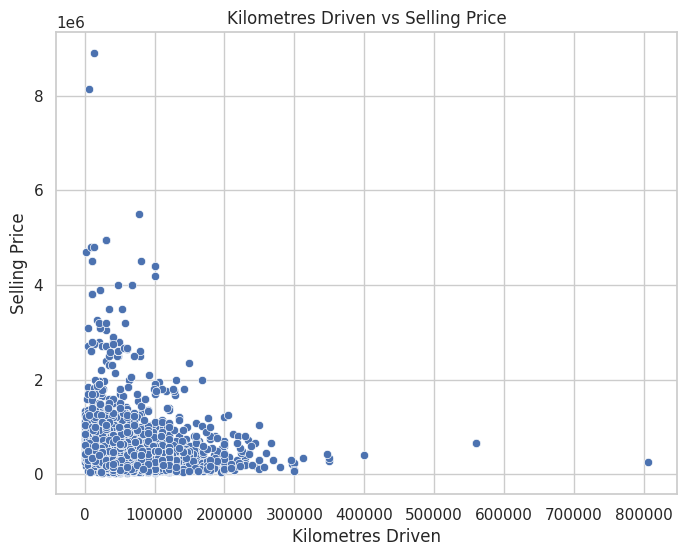

In [ ]:
# ============================================================
# 8. SELLING PRICE VS KM DRIVEN
# ============================================================

plt.figure(figsize=(8, 6))
sns.scatterplot(data=car_dataset, x="km_driven", y="selling_price")
plt.xlabel("Kilometres Driven")
plt.ylabel("Selling Price")
plt.title("Kilometres Driven vs Selling Price")
plt.show()

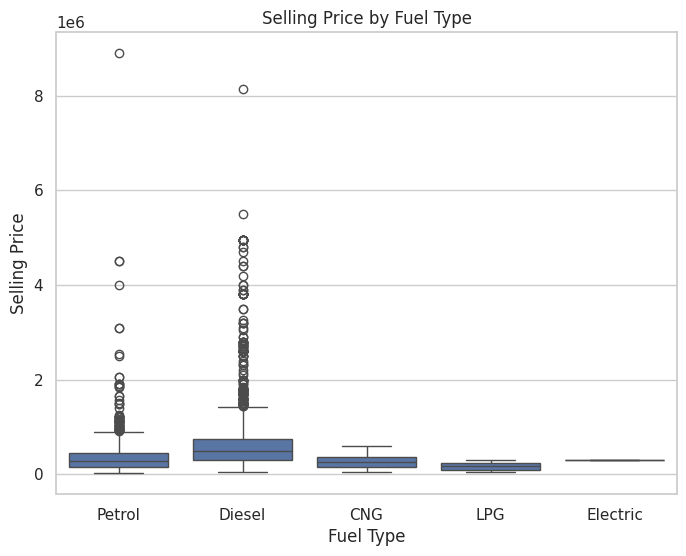

In [ ]:
# ============================================================
# 9. SELLING PRICE BY FUEL TYPE
# ============================================================

plt.figure(figsize=(8, 6))
sns.boxplot(data=car_dataset, x="fuel", y="selling_price")
plt.xlabel("Fuel Type")
plt.ylabel("Selling Price")
plt.title("Selling Price by Fuel Type")
plt.show()

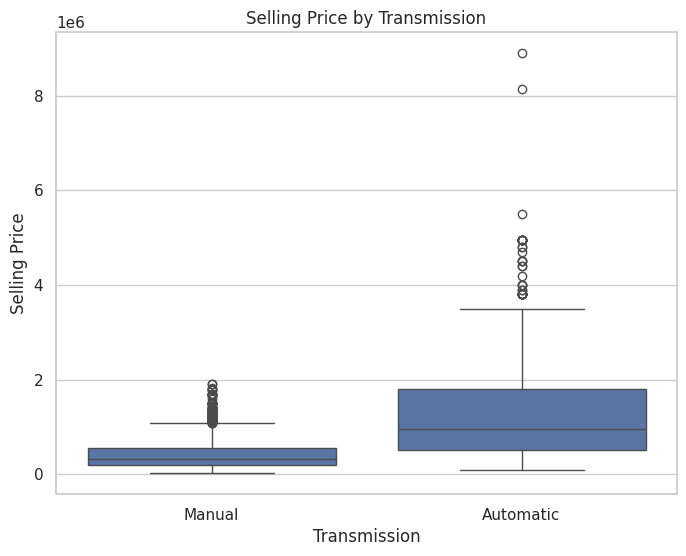

In [ ]:
# ============================================================
# 10. SELLING PRICE BY TRANSMISSION
# ============================================================

plt.figure(figsize=(8, 6))
sns.boxplot(data=car_dataset, x="transmission", y="selling_price")
plt.xlabel("Transmission")
plt.ylabel("Selling Price")
plt.title("Selling Price by Transmission")
plt.show()

In [ ]:
# ============================================================
# 11. FEATURE ENGINEERING
# ============================================================

# Extract brand from car name
car_dataset["brand"] = car_dataset["name"].str.split().str[0]

# Extract first two words as an approximate model identifier
car_dataset["model"] = (
    car_dataset["name"]
    .str.split()
    .str[:2]
    .str.join(" ")
)

display(car_dataset[["name", "brand", "model"]].head(10))

,name,brand,model
0,Maruti 800 AC,Maruti,Maruti 800
1,Maruti Wagon R LXI Minor,Maruti,Maruti Wagon
2,Hyundai Verna 1.6 SX,Hyundai,Hyundai Verna
3,Datsun RediGO T Option,Datsun,Datsun RediGO
4,Honda Amaze VX i-DTEC,Honda,Honda Amaze
5,Maruti Alto LX BSIII,Maruti,Maruti Alto
6,Hyundai Xcent 1.2 Kappa S,Hyundai,Hyundai Xcent
7,Tata Indigo Grand Petrol,Tata,Tata Indigo
8,Hyundai Creta 1.6 VTVT S,Hyundai,Hyundai Creta
9,Maruti Celerio Green VXI,Maruti,Maruti Celerio


In [ ]:
# ============================================================
# 12. DEFINE FEATURES AND TARGET
# ============================================================

X = car_dataset.drop("selling_price", axis=1)
Y = car_dataset["selling_price"]

print("Feature shape:", X.shape)
print("Target shape:", Y.shape)

Feature shape: (4340, 9)
Target shape: (4340,)


In [ ]:
# ============================================================
# 13. TRAIN-TEST SPLIT
# ============================================================

X_train, X_test, Y_train, Y_test = train_test_split(
    X,
    Y,
    test_size=0.1,
    random_state=2
)

print("Training observations:", X_train.shape[0])
print("Testing observations:", X_test.shape[0])

Training observations: 3906
Testing observations: 434


In [ ]:
# ============================================================
# 14. DEFINE NUMERICAL AND CATEGORICAL FEATURES
# ============================================================

numerical_columns = [
    "year",
    "km_driven"
]

categorical_columns = [
    "name",
    "brand",
    "model",
    "fuel",
    "seller_type",
    "transmission",
    "owner"
]

In [ ]:
# ============================================================
# 15. PREPROCESSING
# ============================================================

preprocessor = ColumnTransformer(
    transformers=[
        (
            "numerical",
            StandardScaler(),
            numerical_columns
        ),
        (
            "categorical",
            OneHotEncoder(
                handle_unknown="ignore",
                min_frequency=2
            ),
            categorical_columns
        )
    ]
)

In [ ]:
# ============================================================
# 16. EVALUATION FUNCTION
# ============================================================

def regression_metrics(y_true, y_pred):
    mse = mean_squared_error(y_true, y_pred)
    return {
        "R²": r2_score(y_true, y_pred),
        "MAE": mean_absolute_error(y_true, y_pred),
        "MSE": mse,
        "RMSE": np.sqrt(mse),
        "MAPE (%)": mean_absolute_percentage_error(y_true, y_pred) * 100
    }

In [ ]:
# ============================================================
# 17. LINEAR REGRESSION
# ============================================================

linear_model = Pipeline(
    steps=[
        ("preprocessor", preprocessor),
        ("model", LinearRegression())
    ]
)

linear_model.fit(X_train, Y_train)

linear_train_prediction = linear_model.predict(X_train)
linear_test_prediction = linear_model.predict(X_test)

linear_train_metrics = regression_metrics(
    Y_train, linear_train_prediction
)

linear_test_metrics = regression_metrics(
    Y_test, linear_test_prediction
)

print("LINEAR REGRESSION - TRAIN")
print(linear_train_metrics)

print("\nLINEAR REGRESSION - TEST")
print(linear_test_metrics)

LINEAR REGRESSION - TRAIN
{'R²': 0.9162663651360473, 'MAE': 69378.91419817263, 'MSE': 27993526688.272858, 'RMSE': np.float64(167312.66147029298), 'MAPE (%)': 23.901186468292856}

LINEAR REGRESSION - TEST
{'R²': 0.8178539915110569, 'MAE': 103229.4734666123, 'MSE': 61360676515.57308, 'RMSE': np.float64(247710.87282469674), 'MAPE (%)': 26.98159810881524}


In [ ]:
# ============================================================
# 18. LASSO REGRESSION
# ============================================================

lasso_model = Pipeline(
    steps=[
        ("preprocessor", preprocessor),
        (
            "model",
            Lasso(
                alpha=0.1,
                max_iter=10000
            )
        )
    ]
)

lasso_model.fit(X_train, Y_train)

lasso_train_prediction = lasso_model.predict(X_train)
lasso_test_prediction = lasso_model.predict(X_test)

lasso_train_metrics = regression_metrics(
    Y_train, lasso_train_prediction
)

lasso_test_metrics = regression_metrics(
    Y_test, lasso_test_prediction
)

print("LASSO REGRESSION - TRAIN")
print(lasso_train_metrics)

print("\nLASSO REGRESSION - TEST")
print(lasso_test_metrics)

LASSO REGRESSION - TRAIN
{'R²': 0.9162662459017366, 'MAE': 69387.55971944529, 'MSE': 27993566550.25741, 'RMSE': np.float64(167312.7805944824), 'MAPE (%)': 23.901772068200227}

LASSO REGRESSION - TEST
{'R²': 0.8258553831099954, 'MAE': 101726.18854417023, 'MSE': 58665197181.988365, 'RMSE': np.float64(242208.9948412081), 'MAPE (%)': 26.60695225537365}


/usr/local/lib/python3.13/dist-packages/sklearn/linear_model/_coordinate_descent.py:656: ConvergenceWarning: Objective did not converge. You might want to increase the number of iterations. Duality gap: 13045827113952.875, tolerance: 130583982675.59958
  model = cd_fast.sparse_enet_coordinate_descent(


In [ ]:
# ============================================================
# 19. RIDGE REGRESSION + GRIDSEARCHCV
# ============================================================

ridge_pipeline = Pipeline(
    steps=[
        ("preprocessor", preprocessor),
        ("model", Ridge())
    ]
)

ridge_parameters = {
    "model__alpha": [
        0.01,
        0.1,
        1,
        10,
        100,
        1000
    ]
}

ridge_grid = GridSearchCV(
    estimator=ridge_pipeline,
    param_grid=ridge_parameters,
    cv=5,
    scoring="r2",
    n_jobs=-1
)

ridge_grid.fit(X_train, Y_train)

print("Best Ridge parameter:")
print(ridge_grid.best_params_)

print("\nBest cross-validation R²:")
print(ridge_grid.best_score_)

Best Ridge parameter:
{'model__alpha': 1}

Best cross-validation R²:
0.8259416518104301


In [ ]:
# ============================================================
# 20. RIDGE PREDICTIONS AND METRICS
# ============================================================

ridge_train_prediction = ridge_grid.predict(X_train)
ridge_test_prediction = ridge_grid.predict(X_test)

ridge_train_metrics = regression_metrics(
    Y_train, ridge_train_prediction
)

ridge_test_metrics = regression_metrics(
    Y_test, ridge_test_prediction
)

print("RIDGE REGRESSION - TRAIN")
print(ridge_train_metrics)

print("\nRIDGE REGRESSION - TEST")
print(ridge_test_metrics)

RIDGE REGRESSION - TRAIN
{'R²': 0.8963858145964458, 'MAE': 83046.91798282709, 'MSE': 34639920613.63052, 'RMSE': np.float64(186118.02871734518), 'MAPE (%)': 28.67320767400438}

RIDGE REGRESSION - TEST
{'R²': 0.8576084412694359, 'MAE': 100497.98815945508, 'MSE': 47968343892.338135, 'RMSE': np.float64(219016.7662356883), 'MAPE (%)': 28.814197437547364}


In [ ]:
# ============================================================
# 21. ADJUSTED R²
# ============================================================

def adjusted_r2(r2, n, p):
    return 1 - (1 - r2) * (n - 1) / (n - p - 1)

# Number of predictors after preprocessing
p = (
    ridge_grid.best_estimator_
    .named_steps["preprocessor"]
    .transform(X_train)
    .shape[1]
)

n_train = len(Y_train)
n_test = len(Y_test)

linear_train_adj_r2 = adjusted_r2(
    linear_train_metrics["R²"], n_train, p
)

linear_test_adj_r2 = adjusted_r2(
    linear_test_metrics["R²"], n_test, p
)

lasso_train_adj_r2 = adjusted_r2(
    lasso_train_metrics["R²"], n_train, p
)

lasso_test_adj_r2 = adjusted_r2(
    lasso_test_metrics["R²"], n_test, p
)

ridge_train_adj_r2 = adjusted_r2(
    ridge_train_metrics["R²"], n_train, p
)

ridge_test_adj_r2 = adjusted_r2(
    ridge_test_metrics["R²"], n_test, p
)

print("Linear Test Adjusted R²:", linear_test_adj_r2)
print("Lasso Test Adjusted R²:", lasso_test_adj_r2)
print("Ridge Test Adjusted R²:", ridge_test_adj_r2)

Linear Test Adjusted R²: 1.1653442802425835
Lasso Test Adjusted R²: 1.158080962501828
Ridge Test Adjusted R²: 1.1292569076107637


In [ ]:
# ============================================================
# 22. MODEL COMPARISON
# ============================================================

comparison = pd.DataFrame({
    "Model": [
        "Linear Regression",
        "Lasso Regression",
        "Ridge Regression"
    ],
    "Test R²": [
        linear_test_metrics["R²"],
        lasso_test_metrics["R²"],
        ridge_test_metrics["R²"]
    ],
    "Adjusted R²": [
        linear_test_adj_r2,
        lasso_test_adj_r2,
        ridge_test_adj_r2
    ],
    "Test MAE": [
        linear_test_metrics["MAE"],
        lasso_test_metrics["MAE"],
        ridge_test_metrics["MAE"]
    ],
    "Test MSE": [
        linear_test_metrics["MSE"],
        lasso_test_metrics["MSE"],
        ridge_test_metrics["MSE"]
    ],
    "Test RMSE": [
        linear_test_metrics["RMSE"],
        lasso_test_metrics["RMSE"],
        ridge_test_metrics["RMSE"]
    ],
    "Test MAPE (%)": [
        linear_test_metrics["MAPE (%)"],
        lasso_test_metrics["MAPE (%)"],
        ridge_test_metrics["MAPE (%)"]
    ]
})

display(comparison.round(3))

,Model,Test R²,Adjusted R²,Test MAE,Test MSE,Test RMSE,Test MAPE (%)
0,Linear Regression,0.818,1.165,103229.473,6.136068e+10,247710.873,26.982
1,Lasso Regression,0.826,1.158,101726.189,5.866520e+10,242208.995,26.607
2,Ridge Regression,0.858,1.129,100497.988,4.796834e+10,219016.766,28.814


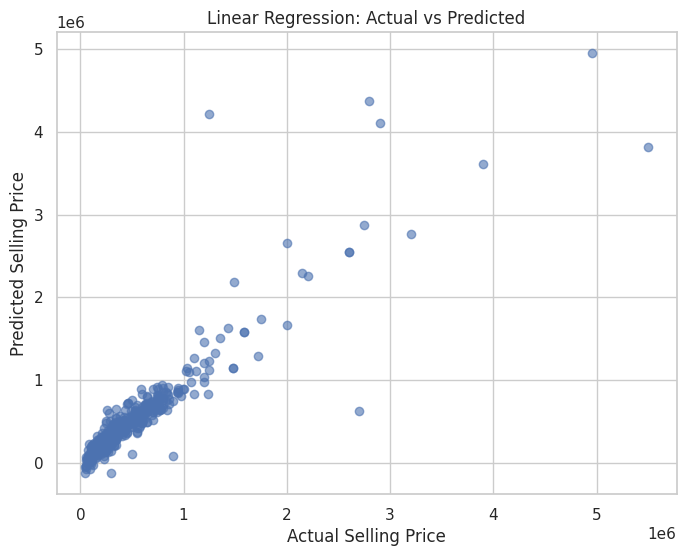

In [ ]:
# ============================================================
# 23. ACTUAL VS PREDICTED - LINEAR REGRESSION
# ============================================================

plt.figure(figsize=(8, 6))
plt.scatter(
    Y_test,
    linear_test_prediction,
    alpha=0.6
)

plt.xlabel("Actual Selling Price")
plt.ylabel("Predicted Selling Price")
plt.title("Linear Regression: Actual vs Predicted")
plt.show()

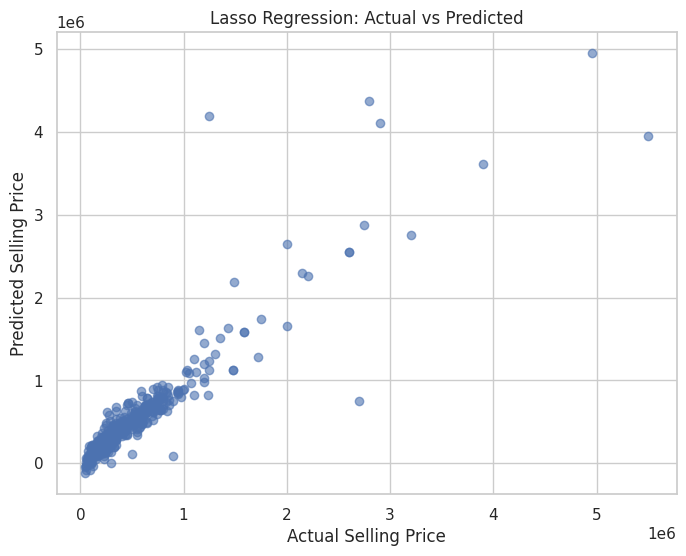

In [ ]:
# ============================================================
# 24. ACTUAL VS PREDICTED - LASSO
# ============================================================

plt.figure(figsize=(8, 6))
plt.scatter(
    Y_test,
    lasso_test_prediction,
    alpha=0.6
)

plt.xlabel("Actual Selling Price")
plt.ylabel("Predicted Selling Price")
plt.title("Lasso Regression: Actual vs Predicted")
plt.show()

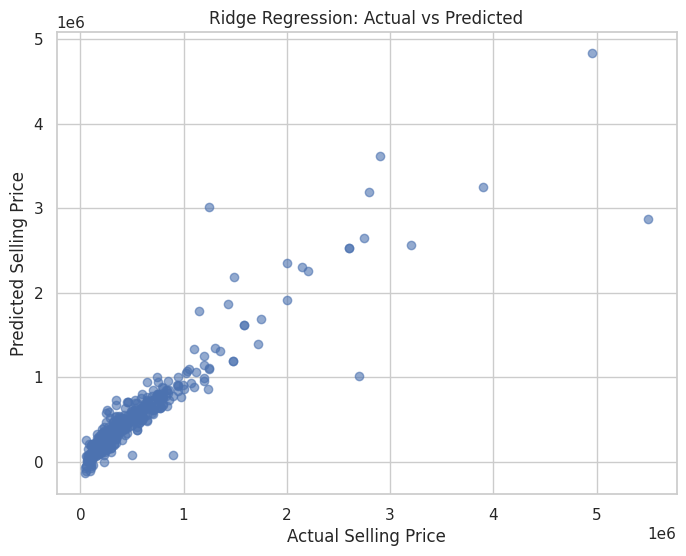

In [ ]:
# ============================================================
# 25. ACTUAL VS PREDICTED - RIDGE
# ============================================================

plt.figure(figsize=(8, 6))
plt.scatter(
    Y_test,
    ridge_test_prediction,
    alpha=0.6
)

plt.xlabel("Actual Selling Price")
plt.ylabel("Predicted Selling Price")
plt.title("Ridge Regression: Actual vs Predicted")
plt.show()

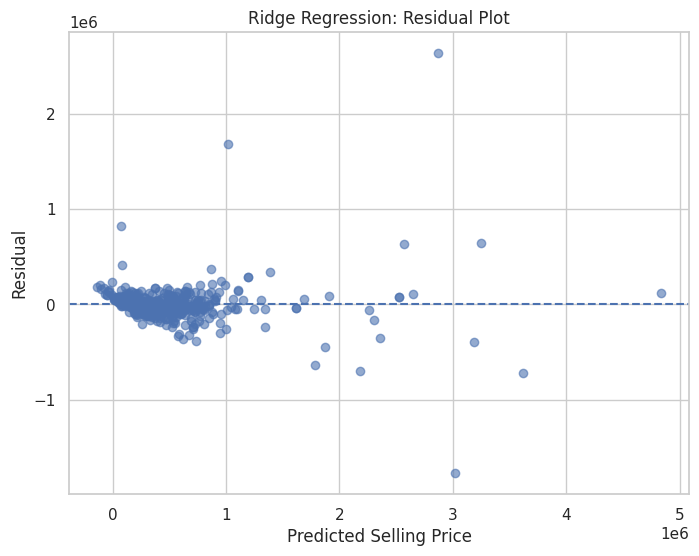

In [ ]:
# ============================================================
# 26. RIDGE RESIDUAL PLOT
# ============================================================

ridge_residuals = Y_test - ridge_test_prediction

plt.figure(figsize=(8, 6))
plt.scatter(
    ridge_test_prediction,
    ridge_residuals,
    alpha=0.6
)

plt.axhline(
    y=0,
    linestyle="--"
)

plt.xlabel("Predicted Selling Price")
plt.ylabel("Residual")
plt.title("Ridge Regression: Residual Plot")
plt.show()

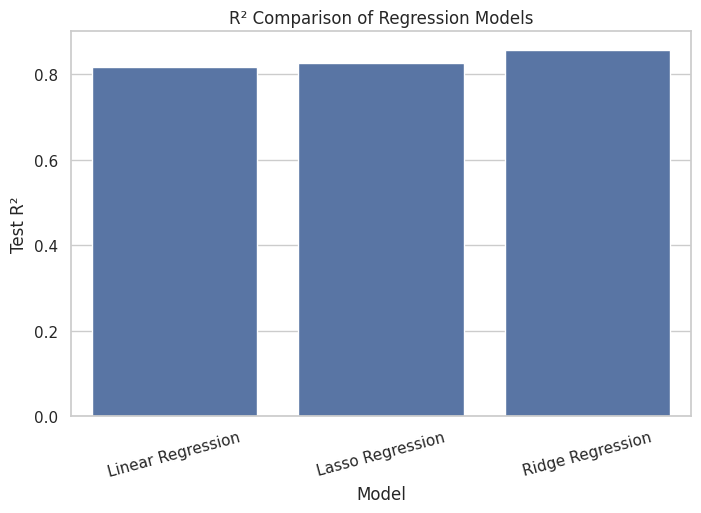

In [ ]:
# ============================================================
# 27. R² COMPARISON
# ============================================================

plt.figure(figsize=(8, 5))

sns.barplot(
    data=comparison,
    x="Model",
    y="Test R²"
)

plt.xlabel("Model")
plt.ylabel("Test R²")
plt.title("R² Comparison of Regression Models")
plt.xticks(rotation=15)

plt.show()

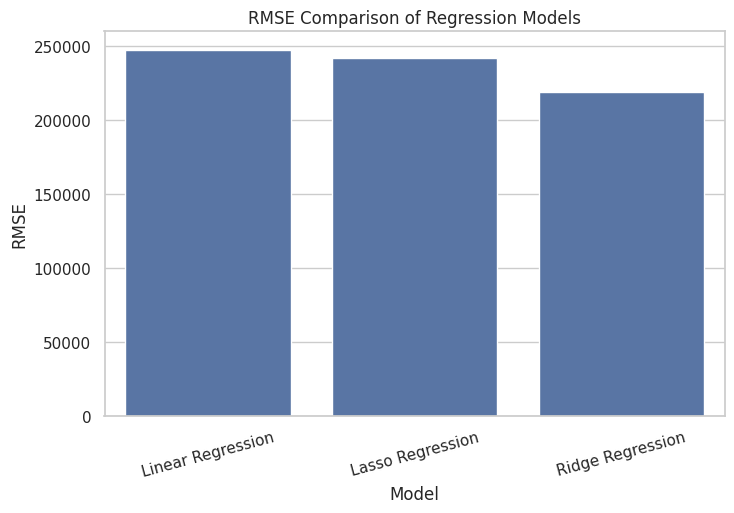

In [ ]:
# ============================================================
# 28. RMSE COMPARISON
# ============================================================

plt.figure(figsize=(8, 5))

sns.barplot(
    data=comparison,
    x="Model",
    y="Test RMSE"
)

plt.xlabel("Model")
plt.ylabel("RMSE")
plt.title("RMSE Comparison of Regression Models")
plt.xticks(rotation=15)

plt.show()

In [ ]:
# ============================================================
# 29. BEST MODEL FOR EACH METRIC
# ============================================================

print("Best R²:")
print(
    comparison.loc[
        comparison["Test R²"].idxmax(),
        "Model"
    ]
)

print("\nLowest MAE:")
print(
    comparison.loc[
        comparison["Test MAE"].idxmin(),
        "Model"
    ]
)

print("\nLowest MSE:")
print(
    comparison.loc[
        comparison["Test MSE"].idxmin(),
        "Model"
    ]
)

print("\nLowest RMSE:")
print(
    comparison.loc[
        comparison["Test RMSE"].idxmin(),
        "Model"
    ]
)

print("\nLowest MAPE:")
print(
    comparison.loc[
        comparison["Test MAPE (%)"].idxmin(),
        "Model"
    ]
)

Best R²:
Ridge Regression

Lowest MAE:
Ridge Regression

Lowest MSE:
Ridge Regression

Lowest RMSE:
Ridge Regression

Lowest MAPE:
Lasso Regression


In [ ]:
# ============================================================
# 30. FINAL SUMMARY
# ============================================================

print("=" * 60)
print("FINAL MODEL PERFORMANCE")
print("=" * 60)

display(comparison.round(3))

print("\nBest Ridge Alpha:")
print(ridge_grid.best_params_)

print("\nBest Cross-Validation R²:")
print(round(ridge_grid.best_score_, 4))

print("\nRidge Test R²:")
print(round(ridge_test_metrics["R²"], 4))

print("\nRidge Test MAE:")
print(round(ridge_test_metrics["MAE"], 2))

print("\nRidge Test RMSE:")
print(round(ridge_test_metrics["RMSE"], 2))

print("\nRidge Test MAPE:")
print(round(ridge_test_metrics["MAPE (%)"], 2), "%")

FINAL MODEL PERFORMANCE


,Model,Test R²,Adjusted R²,Test MAE,Test MSE,Test RMSE,Test MAPE (%)
0,Linear Regression,0.818,1.165,103229.473,6.136068e+10,247710.873,26.982
1,Lasso Regression,0.826,1.158,101726.189,5.866520e+10,242208.995,26.607
2,Ridge Regression,0.858,1.129,100497.988,4.796834e+10,219016.766,28.814



Best Ridge Alpha:
{'model__alpha': 1}

Best Cross-Validation R²:
0.8259

Ridge Test R²:
0.8576

Ridge Test MAE:
100497.99

Ridge Test RMSE:
219016.77

Ridge Test MAPE:
28.81 %
